Task 1: Exploratory Data Analysis- Observations

In [22]:
# imporrting required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [23]:
# loading the superstore sales dataset
from google.colab import files
uploaded = files.upload()
df_raw = pd.read_csv("superstore_sales.csv")
print("Dataset loaded successfully!")
# Dataset dimensions
print("Shape:", df_raw.shape)
# First five records
display(df_raw.head())
# Column information
df_raw.info()
# Statistical summary
display(df_raw.describe())

Dataset loaded successfully!
Shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quanti

,Postal Code,Sales,Quantity,Discount,Profit
count,9983.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55245.233297,229.858001,3.789574,0.156203,28.656896
std,32038.715955,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,57103.000000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [24]:
# Missing values
print("Missing Values:")
print(df_raw.isnull().sum())
# Duplicate records
print("\nDuplicate Records:")
print(df_raw.duplicated().sum())

Missing Values:
Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64

Duplicate Records:
504


In [25]:
# Keep records containing valid order dates
df = df_raw[df_raw["Order Date"].notna()].copy()
# Convert date columns
df["Order Date"] = pd.to_datetime(
    df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], format="%m/%d/%Y")
# Check cleaned dataset
print("Cleaned Dataset Shape:", df.shape)
print("Missing Values:")
print(df.isnull().sum())
print("Duplicate Sales Records:", df.duplicated().sum())

Cleaned Dataset Shape: (9994, 21)
Missing Values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64
Duplicate Sales Records: 0


In [26]:
# Extract year and month for analysis
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.month_name()
display(df[["Order Date", "Year", "Month", "Month Name"]].head())

,Order Date,Year,Month,Month Name
0,2017-11-08,2017,11,November
1,2017-11-08,2017,11,November
2,2017-06-12,2017,6,June
3,2016-10-11,2016,10,October
4,2016-10-11,2016,10,October


In [27]:
#Unique Customers, orders and sum of quantity sold
total_customers = df["Customer ID"].nunique()
total_orders = df["Order ID"].nunique()
total_quantity = df["Quantity"].sum()
print("Total Customers:", total_customers)
print("Total Orders:", total_orders)
print("Total Quantity Sold:", total_quantity)

Total Customers: 793
Total Orders: 5009
Total Quantity Sold: 37873.0


1. Data Cleaning and Preparation

The dataset was inspected and prepared for analysis. Data types, missing values, duplicate records, and date formatting were checked to ensure the data was suitable for further analysis.

,Customer ID,Customer Name,Total_Orders,Total_Quantity,Total_Sales,Total_Profit
0,AA-10315,Alex Avila,5,30.0,5563.560,-362.8825
1,AA-10375,Allen Armold,9,41.0,1056.390,277.3824
2,AA-10480,Andrew Allen,4,36.0,1790.512,435.8274
3,AA-10645,Anna Andreadi,6,64.0,5086.935,857.8033
4,AB-10015,Aaron Bergman,3,13.0,886.156,129.3465
5,AB-10060,Adam Bellavance,8,56.0,7755.620,2054.5885
6,AB-10105,Adrian Barton,10,73.0,14473.571,5444.8055
7,AB-10150,Aimee Bixby,5,37.0,966.710,313.6597
8,AB-10165,Alan Barnes,8,48.0,1113.838,220.8130
9,AB-10255,Alejandro Ballentine,9,39.0,914.532,264.5675


,Customer ID,Customer Name,Total_Orders,Total_Quantity,Total_Sales,Total_Profit
700,SM-20320,Sean Miller,5,50.0,25043.050,-1980.7393
741,TC-20980,Tamara Chand,5,42.0,19052.218,8981.3239
621,RB-19360,Raymond Buch,6,71.0,15117.339,6976.0959
730,TA-21385,Tom Ashbrook,4,36.0,14595.620,4703.7883
6,AB-10105,Adrian Barton,10,73.0,14473.571,5444.8055
434,KL-16645,Ken Lonsdale,12,113.0,14175.229,806.8550
669,SC-20095,Sanjit Chand,9,87.0,14142.334,5757.4119
327,HL-15040,Hunter Lopez,6,50.0,12873.298,5622.4292
683,SE-20110,Sanjit Engle,11,78.0,12209.438,2650.6769
131,CC-12370,Christopher Conant,5,34.0,12129.072,2177.0493


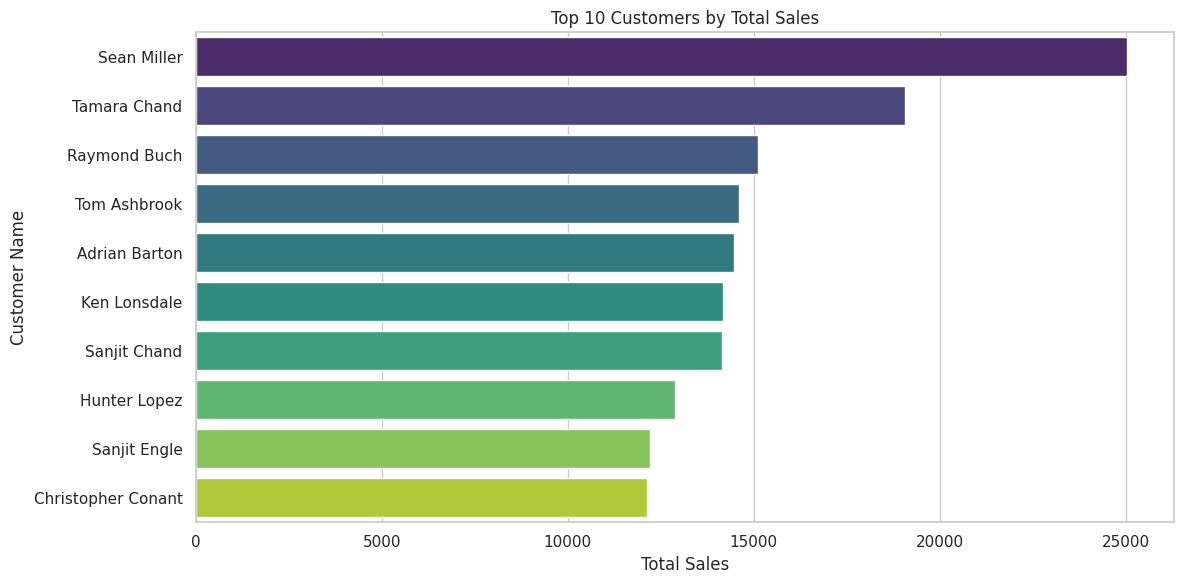

In [28]:
#customer purchase summary
customer_summary = df.groupby(
    ["Customer ID", "Customer Name"]
).agg(
    Total_Orders=("Order ID", "nunique"),
    Total_Quantity=("Quantity", "sum"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).reset_index()
display(customer_summary.head(10))

#top 10 customers
top_customers = customer_summary.sort_values(
    by="Total_Sales",
    ascending=False
).head(10)
display(top_customers)

#visualization of top customers
plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_customers,
    x="Total_Sales",
    y="Customer Name",
    hue="Customer Name",
    palette="viridis",
    legend=False)
plt.title("Top 10 Customers by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Customer Name")
plt.tight_layout()
plt.show()

,Segment,Total_Orders,Total_Sales,Total_Profit,Total_Quantity
0,Consumer,2586,1.161401e+06,134119.2092,19521.0
1,Corporate,1514,7.061464e+05,91979.1340,11608.0
2,Home Office,909,4.296531e+05,60298.6785,6744.0


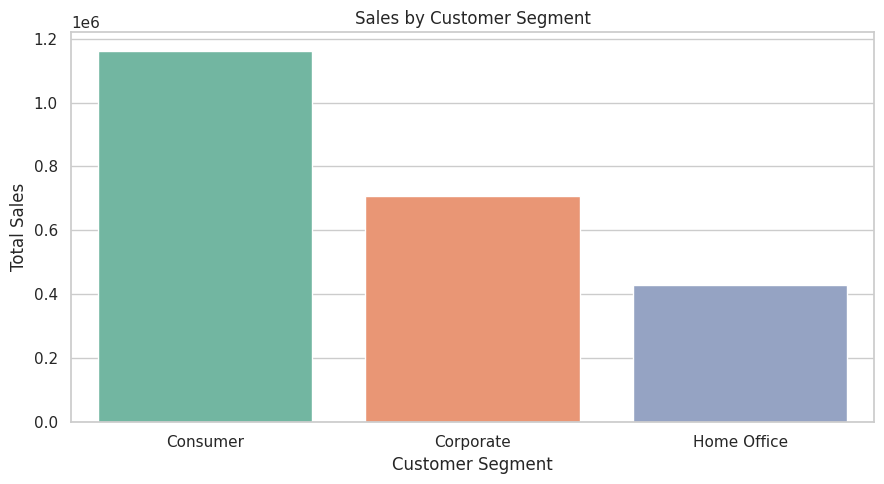

In [29]:
#customer segment analysis
segment_analysis = df.groupby("Segment").agg(
    Total_Orders=("Order ID", "nunique"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()
display(segment_analysis)

#visualization of customer segments
plt.figure(figsize=(9, 5))
sns.barplot(
    data=segment_analysis,
    x="Segment",
    y="Total_Sales",
    hue="Segment",
    palette="Set2",
    legend=False)
plt.title("Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

2. Customer Analysis

The Consumer segment generated the highest sales, followed by Corporate and Home Office.

Sean Miller was the highest-sales customer among the customers analysed.

The analysis of customer orders and purchase behaviour helps identify valuable customers and important customer segments.

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64


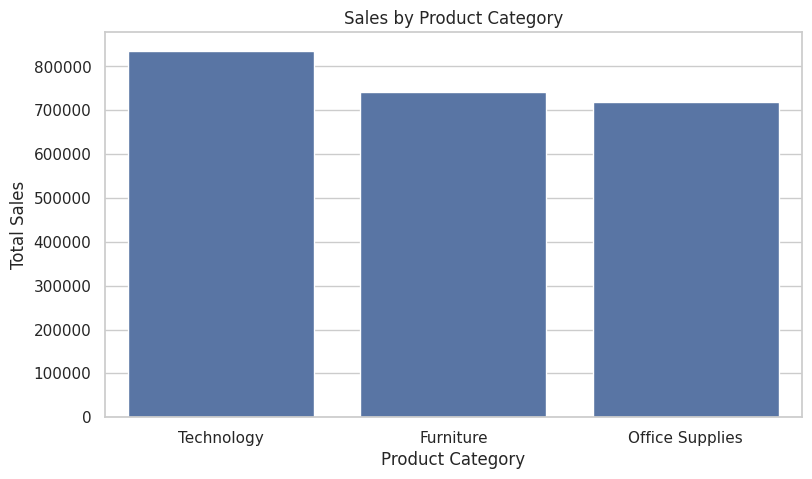

Highest Sales Category: Technology
Lowest Sales Category: Office Supplies


In [30]:
# Sales by Product Category
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
print(category_sales)

#visualization of sales by product category
plt.figure(figsize=(9, 5))
sns.barplot(
    x=category_sales.index,
    y=category_sales.values)
plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.show()

#best and worst performing categories
print("Highest Sales Category:", category_sales.idxmax())
print("Lowest Sales Category:", category_sales.idxmin())

Sub-Category
Phones         330007.0540
Chairs         328449.1030
Storage        223843.6080
Tables         206965.5320
Binders        203412.7330
Machines       189238.6310
Accessories    167380.3180
Copiers        149528.0300
Bookcases      114879.9963
Appliances     107532.1610
Furnishings     91705.1640
Paper           78479.2060
Supplies        46673.5380
Art             27118.7920
Envelopes       16476.4020
Labels          12486.3120
Fasteners        3024.2800
Name: Sales, dtype: float64


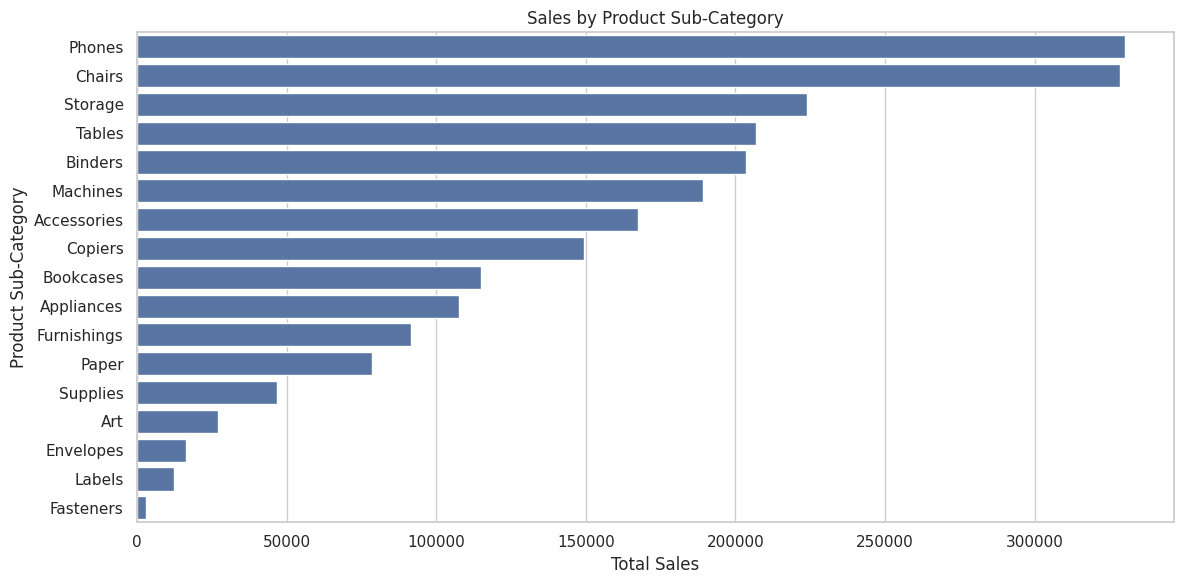

Highest: Phones
Lowest: Fasteners


In [33]:
#sales by product sub category
subcategory_sales=df.groupby(
    "Sub-Category")["Sales"].sum().sort_values(ascending=False)
print(subcategory_sales)

#visualization of sales by product sub category
plt.figure(figsize=(12,6))
sns.barplot(
    x=subcategory_sales.values,
    y=subcategory_sales.index)
plt.title("Sales by Product Sub-Category")
plt.xlabel("Total Sales")
plt.ylabel("Product Sub-Category")
plt.tight_layout()
plt.show()

#highest and lowest by subcategory
print("Highest:", subcategory_sales.idxmax())
print("Lowest:", subcategory_sales.idxmin())

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


/tmp/ipykernel_7067/2088049725.py:14: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


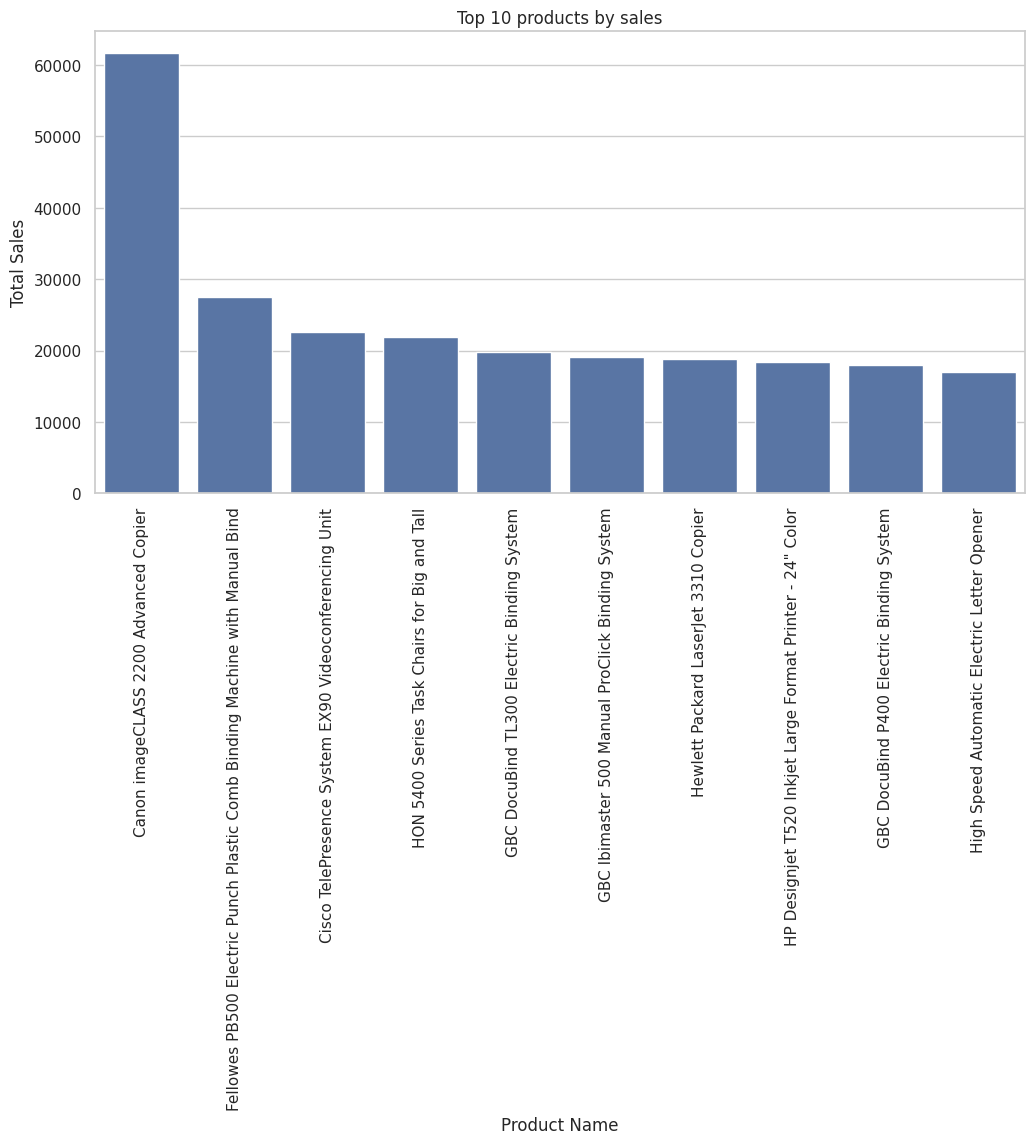

In [34]:
#top 10 products by sales
top_products=df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10)
print(top_products)

#visualization of top 10 products
plt.figure(figsize=(12,6))
sns.barplot(
    x=top_products.index,
    y=top_products.values)
plt.title("Top 10 products by sales")
plt.xlabel("Product Name")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [35]:
#bottom 10 products
bottom_products = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values()
    .head(10))
print(bottom_products)

Product Name
Eureka Disposable Bags for Sanitaire Vibra Groomer I Upright Vac    1.624
Avery 5                                                             5.760
Xerox 20                                                            6.480
Grip Seal Envelopes                                                 7.072
Avery Hi-Liter Pen Style Six-Color Fluorescent Set                  7.700
Avery Hi-Liter Comfort Grip Fluorescent Highlighter, Yellow Ink     7.800
Xerox 1989                                                          7.968
4009 Highlighters                                                   8.040
Stockwell Gold Paper Clips                                          8.096
Newell 308                                                          8.400
Name: Sales, dtype: float64


3. Product Analysis

Technology generated the highest sales among the three product categories.

Phones recorded the highest sales among sub-categories, while Fasteners recorded the lowest.

The Canon imageCLASS 2200 Advanced Copier was the highest-selling product in the top-products analysis.

These findings indicate that Technology products, particularly Phones, contribute significantly to overall sales.

Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64


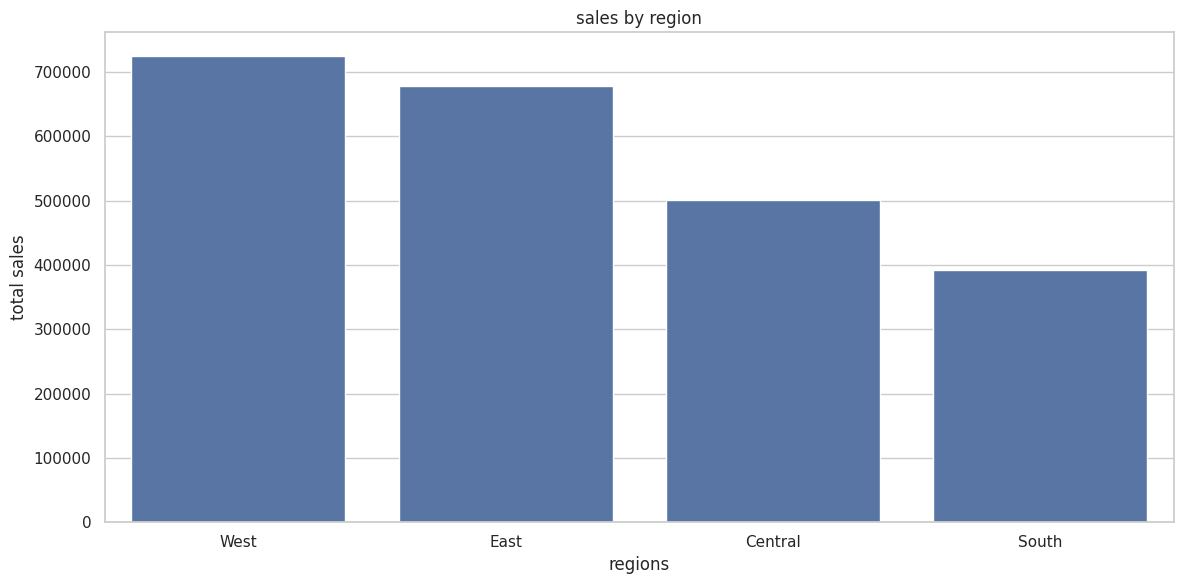

highest: West
lowest: South


In [36]:
#sales by regions
region_sales=df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
print(region_sales)

#visualization of egion sales
plt.figure(figsize=(12,6))
sns.barplot(
    x=region_sales.index,
    y=region_sales.values)
plt.title("sales by region")
plt.xlabel("regions")
plt.ylabel("total sales")
plt.tight_layout()
plt.show()

#highest and lowest
print("highest:", region_sales.idxmax())
print("lowest:", region_sales.idxmin())

State
California      457687.6315
New York        310876.2710
Texas           170188.0458
Washington      138641.2700
Pennsylvania    116511.9140
Name: Sales, dtype: float64


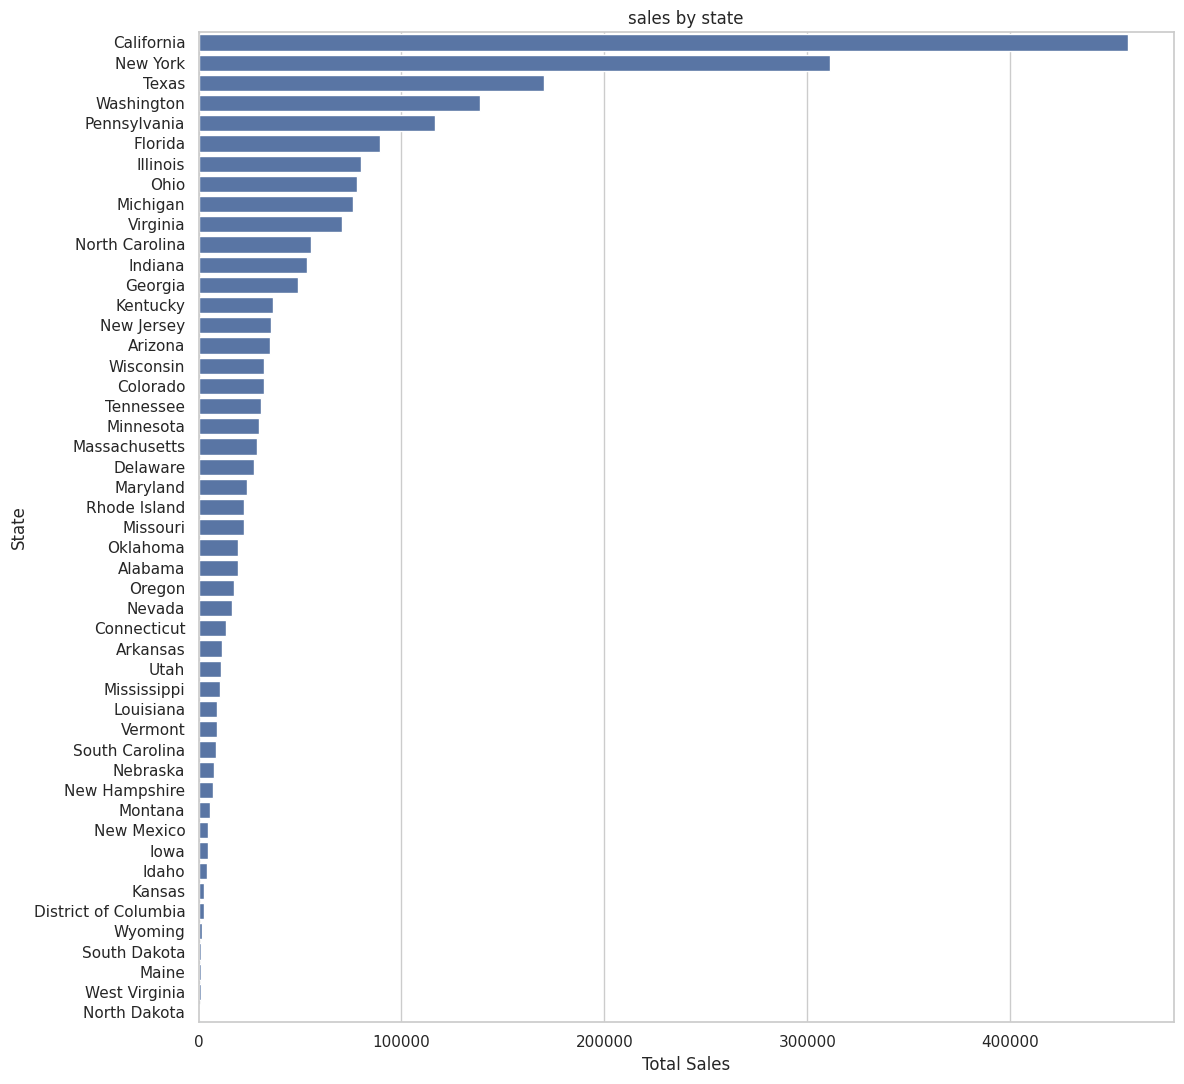

highest: California
lowest North Dakota


In [41]:
#sales by state
state_sales=df.groupby("State")["Sales"].sum().sort_values(ascending=False)
print(state_sales.head())
#visualization of sales by state
plt.figure(figsize=(12,11))
sns.barplot(
    x=state_sales.values,
    y=state_sales.index)
plt.title("sales by state")
plt.xlabel("Total Sales")
plt.ylabel("State")
plt.tight_layout()
plt.show()

#highest and lowest
print("highest:",state_sales.idxmax())
print("lowest",state_sales.idxmin())

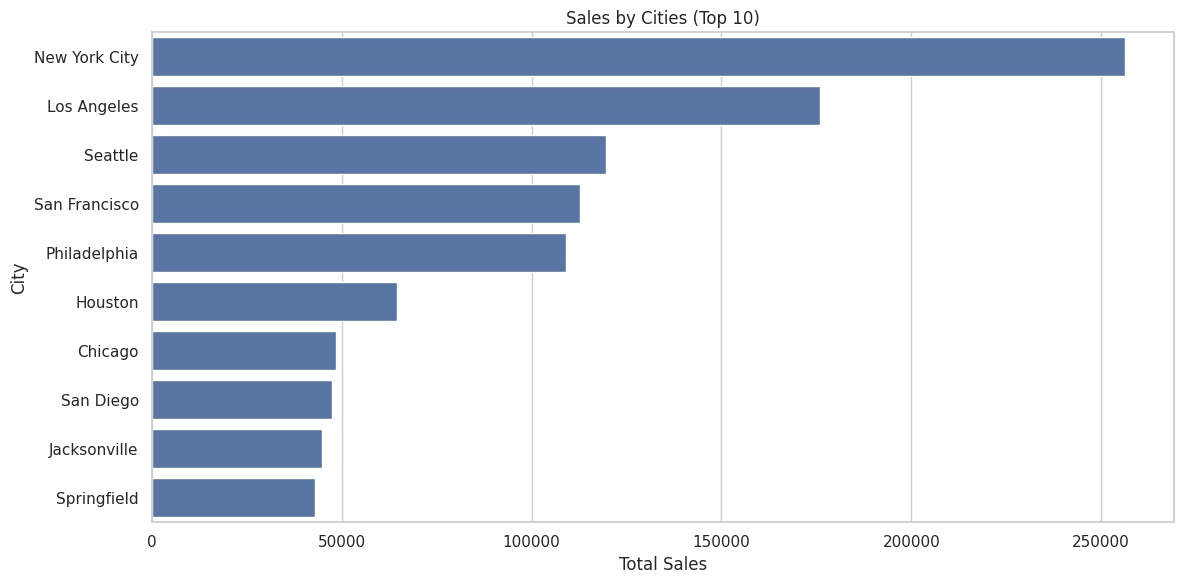

Highest: New York City
Lowest: Abilene


In [42]:
# Sales by cities
city_sales = df.groupby("City")["Sales"].sum().sort_values(ascending=False)

# Top 10 cities
top_city = city_sales.head(10)

# Visualize
plt.figure(figsize=(12, 6))
sns.barplot(
    x=top_city.values,
    y=top_city.index)
plt.title("Sales by Cities (Top 10)")
plt.xlabel("Total Sales")
plt.ylabel("City")
plt.tight_layout()
plt.show()

# Highest and lowest
print("Highest:", city_sales.idxmax())
print("Lowest:", city_sales.idxmin())


4. Regional Analysis

The West region recorded the highest sales, while the South region recorded the lowest.

New York City generated the highest city-wise sales, while Abilene recorded the lowest.

The West region also generated the highest profit, whereas the Central region generated the lowest profit.

All regions generated positive total profit.

Year
2015    484247.4981
2016    470532.5090
2017    609205.5980
2018    733215.2552
Name: Sales, dtype: float64


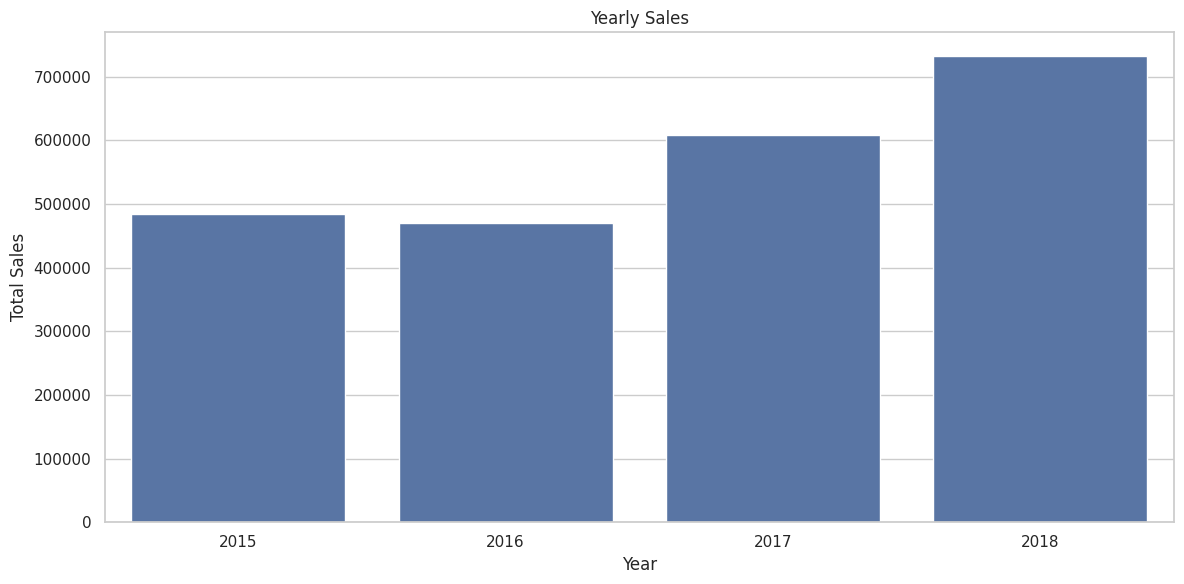

highest: 2018
lowest: 2016


In [44]:
#yearly sales
yearly_sales=df.groupby("Year")["Sales"].sum().sort_index()
print(yearly_sales)
#yearly sales graph
plt.figure(figsize=(12,6))
sns.barplot(
x=yearly_sales.index,
y=yearly_sales.values)
plt.title("Yearly Sales")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()
#highest and lowest
print("highest:",yearly_sales.idxmax())
print("lowest:",yearly_sales.idxmin())

Month
1     94924.8356
2     59751.2514
3    205005.4888
4    137762.1286
5    155028.8117
Name: Sales, dtype: float64


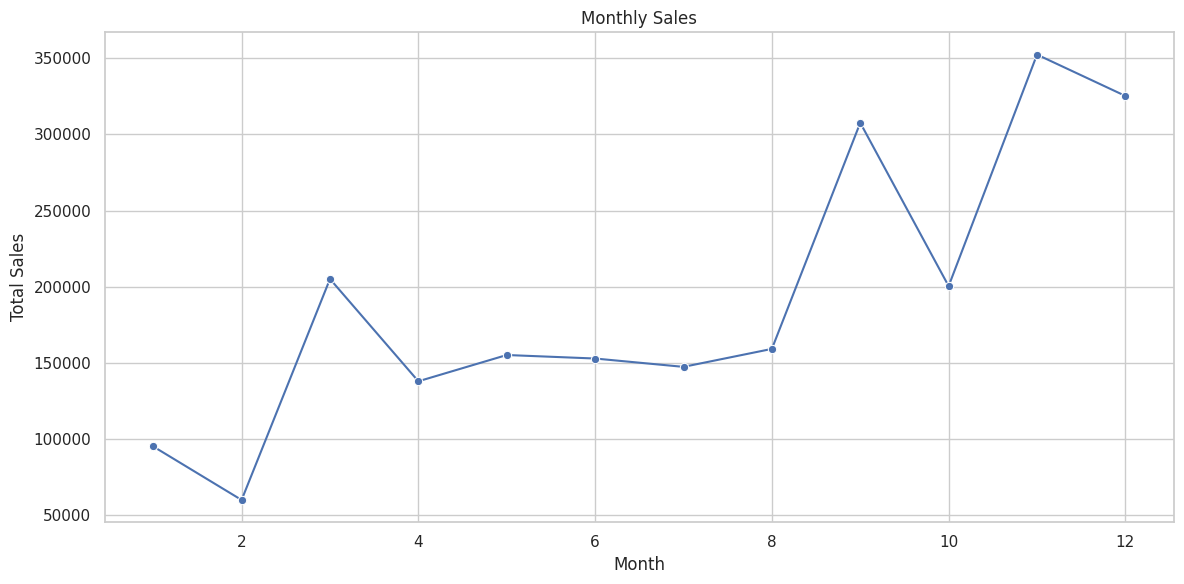

highest: 11
lowest: 2


In [48]:
#monthly sales
monthly_sales=df.groupby("Month")["Sales"].sum().sort_index()
print(monthly_sales.head())
#monthly sales graph
plt.figure(figsize=(12,6))
sns.lineplot(
x=monthly_sales.index,
y=monthly_sales.values,
              marker="o")
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()
#highest and lowest
print("highest:",monthly_sales.idxmax())
print("lowest:",monthly_sales.idxmin())

Year  Month
2015  1        14236.895
      2         4519.892
      3        55691.009
      4        28295.345
      5        23648.287
Name: Sales, dtype: float64


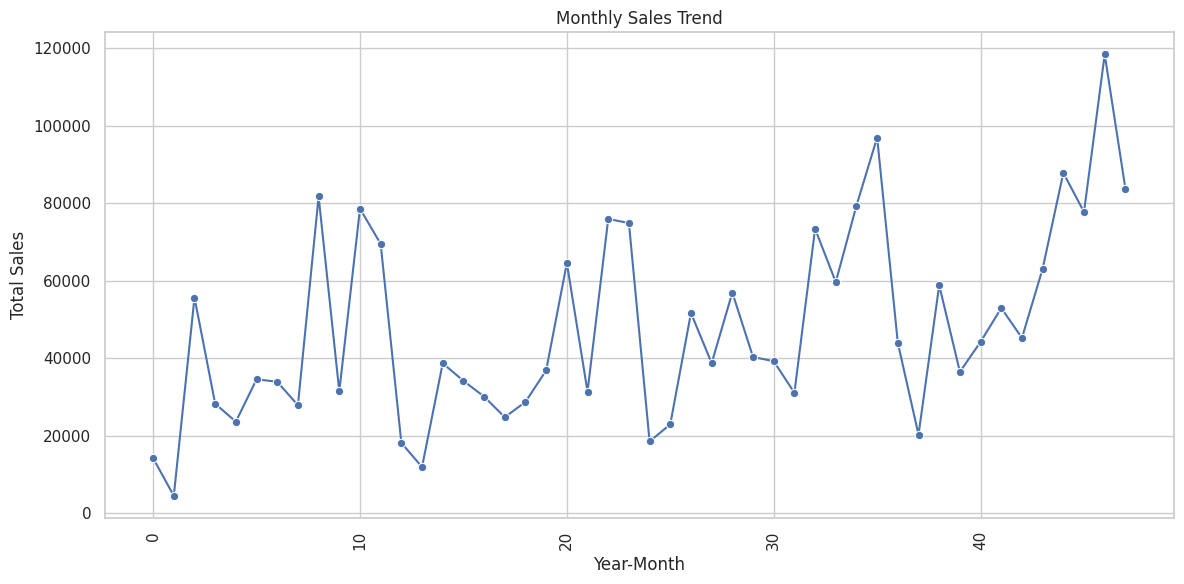

In [51]:
#monthly sales trend
monthly_sales_trend = df.groupby(["Year", "Month"])["Sales"].sum().sort_index()
print(monthly_sales_trend.head())
#visualization
plt.figure(figsize=(12,6))
sns.lineplot(
    x=range(len(monthly_sales_trend)),
    y=monthly_sales_trend.values,
    marker="o"
)
plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

5. Time-Based Sales Analysis

June recorded the highest monthly sales, while February recorded the lowest.

The yearly and monthly analysis helps identify sales patterns and periods of stronger or weaker business performance.

These trends can help businesses plan inventory, staffing, and promotional activities.

In [52]:
# Overall Profit Analysis
total_profit = df["Profit"].sum()
print("Total Profit:", total_profit)

total_sales = df["Sales"].sum()
print("Total Sales:", total_sales)

avg_profit = df["Profit"].mean()
print("Average Profit:", round(avg_profit, 2))

profit_margin = round((total_profit / total_sales) * 100, 2)
print("Profit Margin:", profit_margin, "%")


Total Profit: 286397.0217
Total Sales: 2297200.8603
Average Profit: 28.66
Profit Margin: 12.47 %


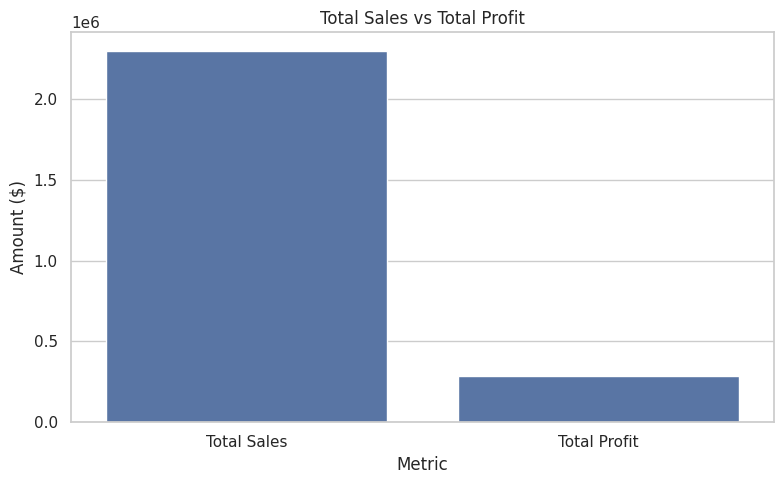

In [53]:
# Sales vs Profit Chart
comparison = pd.DataFrame({
    "Metric": ["Total Sales", "Total Profit"],
    "Amount": [total_sales, total_profit]
})
plt.figure(figsize=(8, 5))
sns.barplot(
    data=comparison,
    x="Metric",
    y="Amount"
)
plt.title("Total Sales vs Total Profit")
plt.xlabel("Metric")
plt.ylabel("Amount ($)")
plt.tight_layout()
plt.show()

Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64


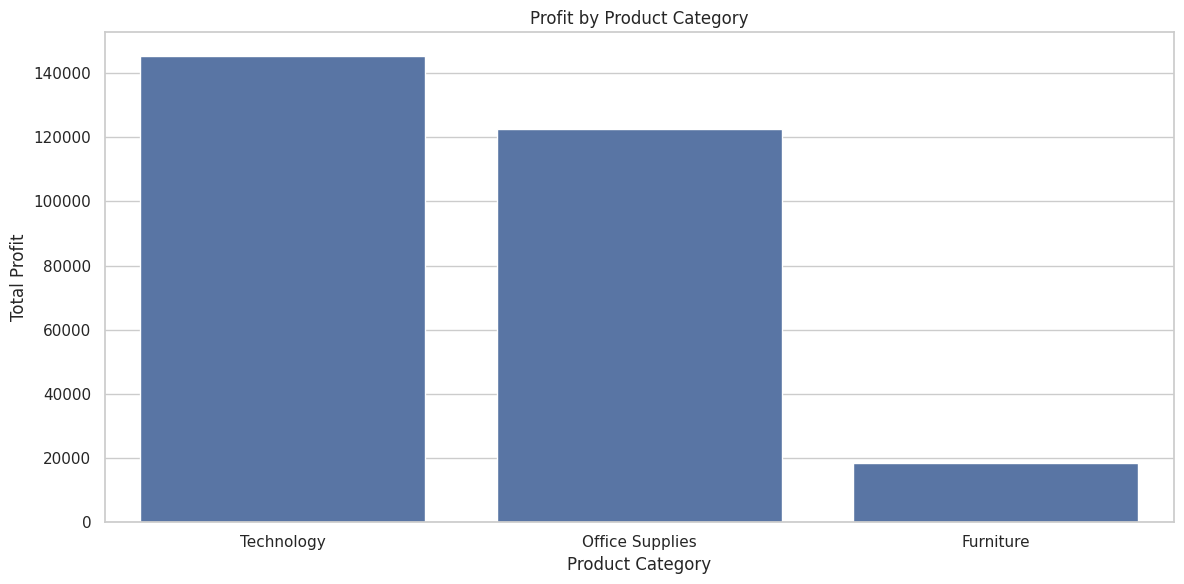

Highest: Technology
Lowest: Furniture


In [54]:
# Profit by Category
category_profit = df.groupby("Category")["Profit"].sum().sort_values(ascending=False)
print(category_profit)
# Visualize
plt.figure(figsize=(12,6))
sns.barplot(
    x=category_profit.index,
    y=category_profit.values)
plt.title("Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")
plt.tight_layout()
plt.show()
# Highest and Lowest
print("Highest:", category_profit.idxmax())
print("Lowest:", category_profit.idxmin())


Sub-Category
Copiers        55617.8249
Phones         44515.7306
Accessories    41936.6357
Paper          34053.5693
Binders        30221.7633
Name: Profit, dtype: float64


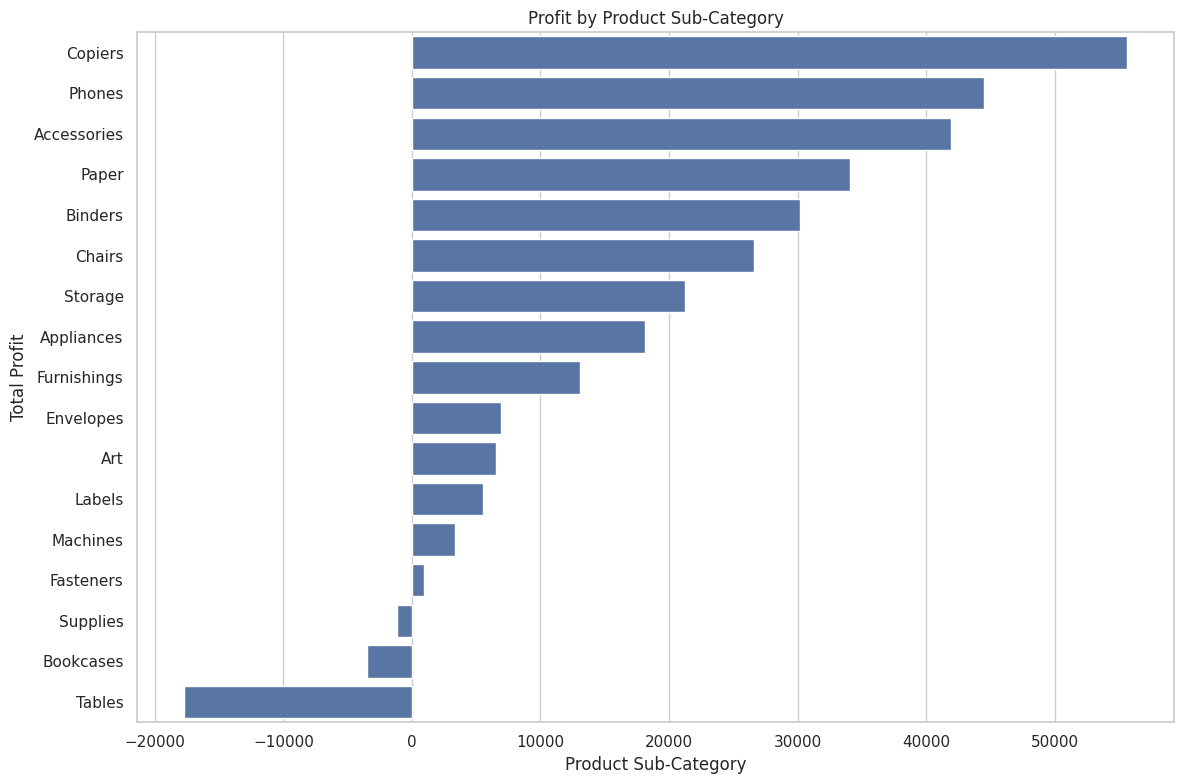

Highest: Copiers
Lowest: Tables


In [56]:
# Profit by sub-Category
subcategory_profit = df.groupby("Sub-Category")["Profit"].sum().sort_values(ascending=False)
print(subcategory_profit.head())
# Visualize
plt.figure(figsize=(12,8))
sns.barplot(
    x=subcategory_profit.values,
    y=subcategory_profit.index)
plt.title("Profit by Product Sub-Category")
plt.xlabel("Product Sub-Category")
plt.ylabel("Total Profit")
plt.tight_layout()
plt.show()
# Highest and Lowest
print("Highest:", subcategory_profit.idxmax())
print("Lowest:", subcategory_profit.idxmin())

Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64


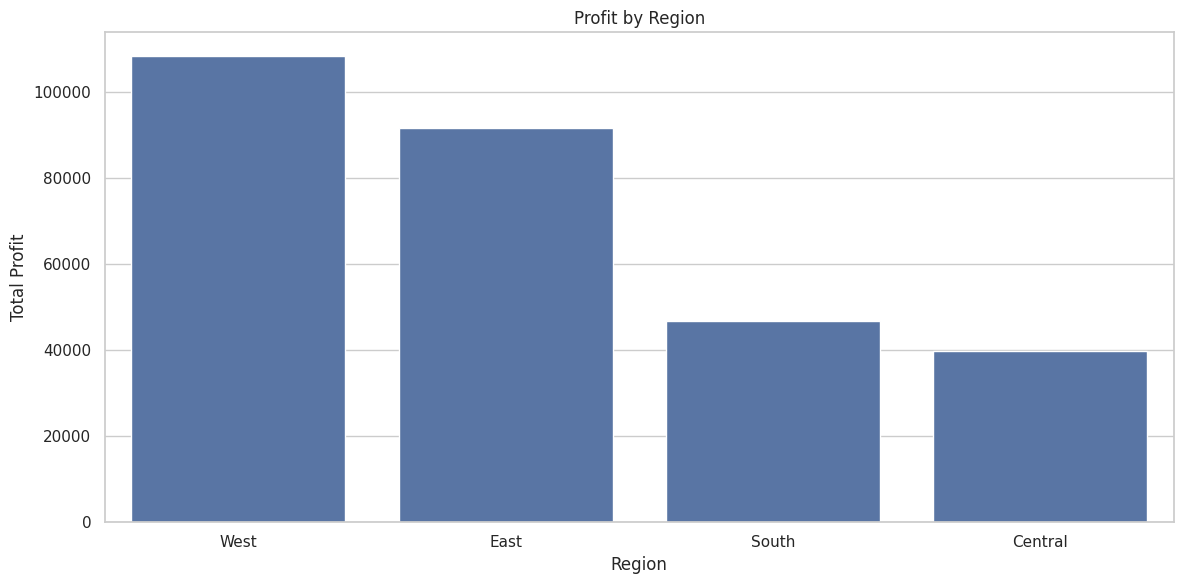

Highest: West
Lowest: Central


In [58]:
# Profit by region
region_profit = df.groupby("Region")["Profit"].sum().sort_values(ascending=False)
print(region_profit)
# Visualize
plt.figure(figsize=(12,6))
sns.barplot(
    x=region_profit.index,
    y=region_profit.values)
plt.title("Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.tight_layout()
plt.show()
# Highest and Lowest
print("Highest:", region_profit.idxmax())
print("Lowest:", region_profit.idxmin())

In [59]:
#products that generate loss
product_profit = df.groupby("Product Name")["Profit"].sum()
loss_products = product_profit[product_profit < 0].sort_values()
print(loss_products.head(10))

Product Name
Cubify CubeX 3D Printer Double Head Print                           -8879.9704
Lexmark MX611dhe Monochrome Laser Printer                           -4589.9730
Cubify CubeX 3D Printer Triple Head Print                           -3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases            -2876.1156
Bush Advantage Collection Racetrack Conference Table                -1934.3976
GBC DocuBind P400 Electric Binding System                           -1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit               -1811.0784
Martin Yale Chadless Opener Electric Letter Opener                  -1299.1836
Balt Solid Wood Round Tables                                        -1201.0581
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables   -1148.4375
Name: Profit, dtype: float64


6. Profitability Analysis

Technology generated the highest total profit among the product categories.

Furniture recorded the lowest total profit.

Supplies, Bookcases, and Tables were among the sub-categories that generated negative profit.

Several individual products also recorded significant losses. The Cubify CubeX 3D Printer Double Head was the largest loss-making product in the analysis, with a loss of approximately $8,879.97.

These findings suggest that product pricing, discounts, and operating costs should be reviewed for loss-making products.

Total discount: 1561.0900000000001
Max discount: 0.8
Min discount: 0.0
Average discount: 0.16
Category
Furniture          0.173923
Office Supplies    0.157285
Technology         0.132323
Name: Discount, dtype: float64


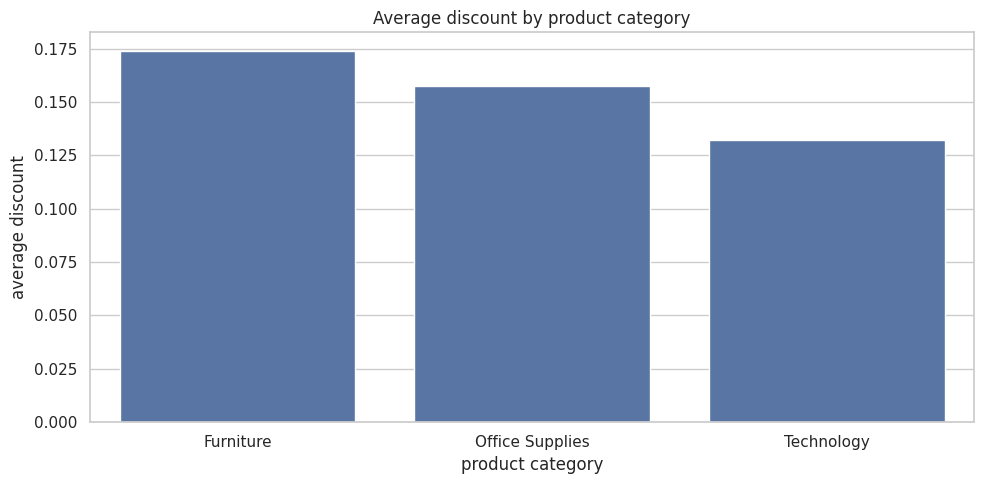

In [60]:
# Total discount
print("Total discount:", df["Discount"].sum())
# Maximum discount
print("Max discount:", df["Discount"].max())
# Minimum discount
print("Min discount:", df["Discount"].min())
# Average discount
print("Average discount:", round(df["Discount"].mean(), 2))
# Average discount by product category
avg_discount = df.groupby("Category")["Discount"].mean()
print(avg_discount)
#visualization
plt.figure(figsize=(10,5))
sns.barplot(
x=avg_discount.index,
y=avg_discount.values)
plt.title("Average discount by product category")
plt.xlabel("product category")
plt.ylabel("average discount")
plt.tight_layout()
plt.show()

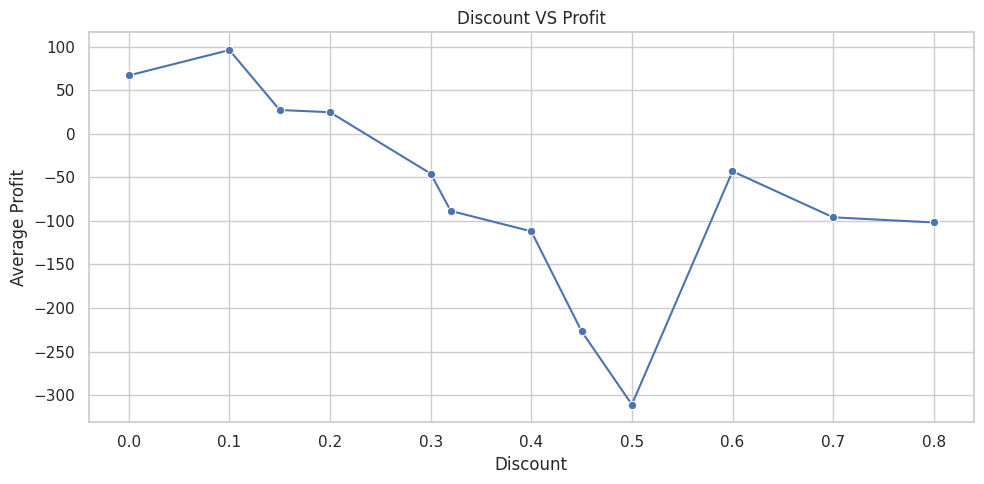

highest: 0.1
lowest: 0.5


In [61]:
#discount vs profit
discount_vs_profit=df.groupby("Discount")["Profit"].mean().sort_index()
sns.lineplot(
x=discount_vs_profit.index,
y=discount_vs_profit.values,
              marker="o")
plt.title("Discount VS Profit")
plt.xlabel("Discount")
plt.ylabel("Average Profit")
plt.tight_layout()
plt.show()
print("highest:",discount_vs_profit.idxmax())
print("lowest:",discount_vs_profit.idxmin())

7. Discount Analysis

The average discount level of 10% recorded the highest average profit.

The 50% discount level recorded the lowest average profit, which was negative.

This indicates that higher discounts may reduce profitability.

Businesses should carefully evaluate discount strategies to maintain sales while protecting profit margins.

Overall Conclusion

The exploratory data analysis helped identify important patterns in customer behaviour, product performance, regional sales, time-based trends, profitability, and discount strategies.

Technology products and the West region showed strong performance, while certain furniture sub-categories and heavily discounted transactions highlighted profitability concerns.

The analysis suggests that the business should focus on its profitable products and regions, review loss-making products, and apply discounts strategically to improve overall profitability.